In [4]:
!pip install -q ultralytics

from google.colab import files
up = files.upload()
zip_name = list(up.keys())[0]
print("업로드됨:", zip_name)

#압축 풀
!rm -rf /content/data
!unzip -q -o "/content/{zip_name}" -d /content/data

import os, random, shutil, glob, yaml
root = "/content/data"

#train/valid/test 분할
imgs = sorted(glob.glob(f"{root}/train/images/*"))
random.seed(42)
random.shuffle(imgs)
n = len(imgs)
n_val, n_test = int(n * 0.2), int(n * 0.1)
splits = {"valid": imgs[:n_val], "test": imgs[n_val:n_val + n_test]}

for split, fs in splits.items():
    os.makedirs(f"{root}/{split}/images", exist_ok=True)
    os.makedirs(f"{root}/{split}/labels", exist_ok=True)
    for img in fs:
        name = os.path.splitext(os.path.basename(img))[0]
        shutil.move(img, f"{root}/{split}/images/")
        lbl = f"{root}/train/labels/{name}.txt"
        if os.path.exists(lbl):
            shutil.move(lbl, f"{root}/{split}/labels/")

for s in ["train", "valid", "test"]:
    print(s, len(os.listdir(f"{root}/{s}/images")))

p = f"{root}/data.yaml"
d = yaml.safe_load(open(p))
d["path"] = root
d["train"], d["val"], d["test"] = "train/images", "valid/images", "test/images"
yaml.safe_dump(d, open(p, "w"))
print(d["names"])

# 학습
from ultralytics import YOLO
model = YOLO("yolov8n.pt")
model.train(data=p, epochs=100, imgsz=640, batch=16, patience=20)

Saving My First Project.v1i.yolov8.zip to My First Project.v1i.yolov8 (2).zip
업로드됨: My First Project.v1i.yolov8 (2).zip
train 189
valid 53
test 26
['car', 'dog', 'person']
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7aec06190670>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [5]:
from ultralytics import YOLO
model = YOLO("yolov8n.pt")
model.train(
    data="/content/data/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    patience=50,
    freeze=10,
    name="final",
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=final, nbs=64, nms=None, opset=None, optimize=False, optimizer=aut

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7aed41eadb70>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

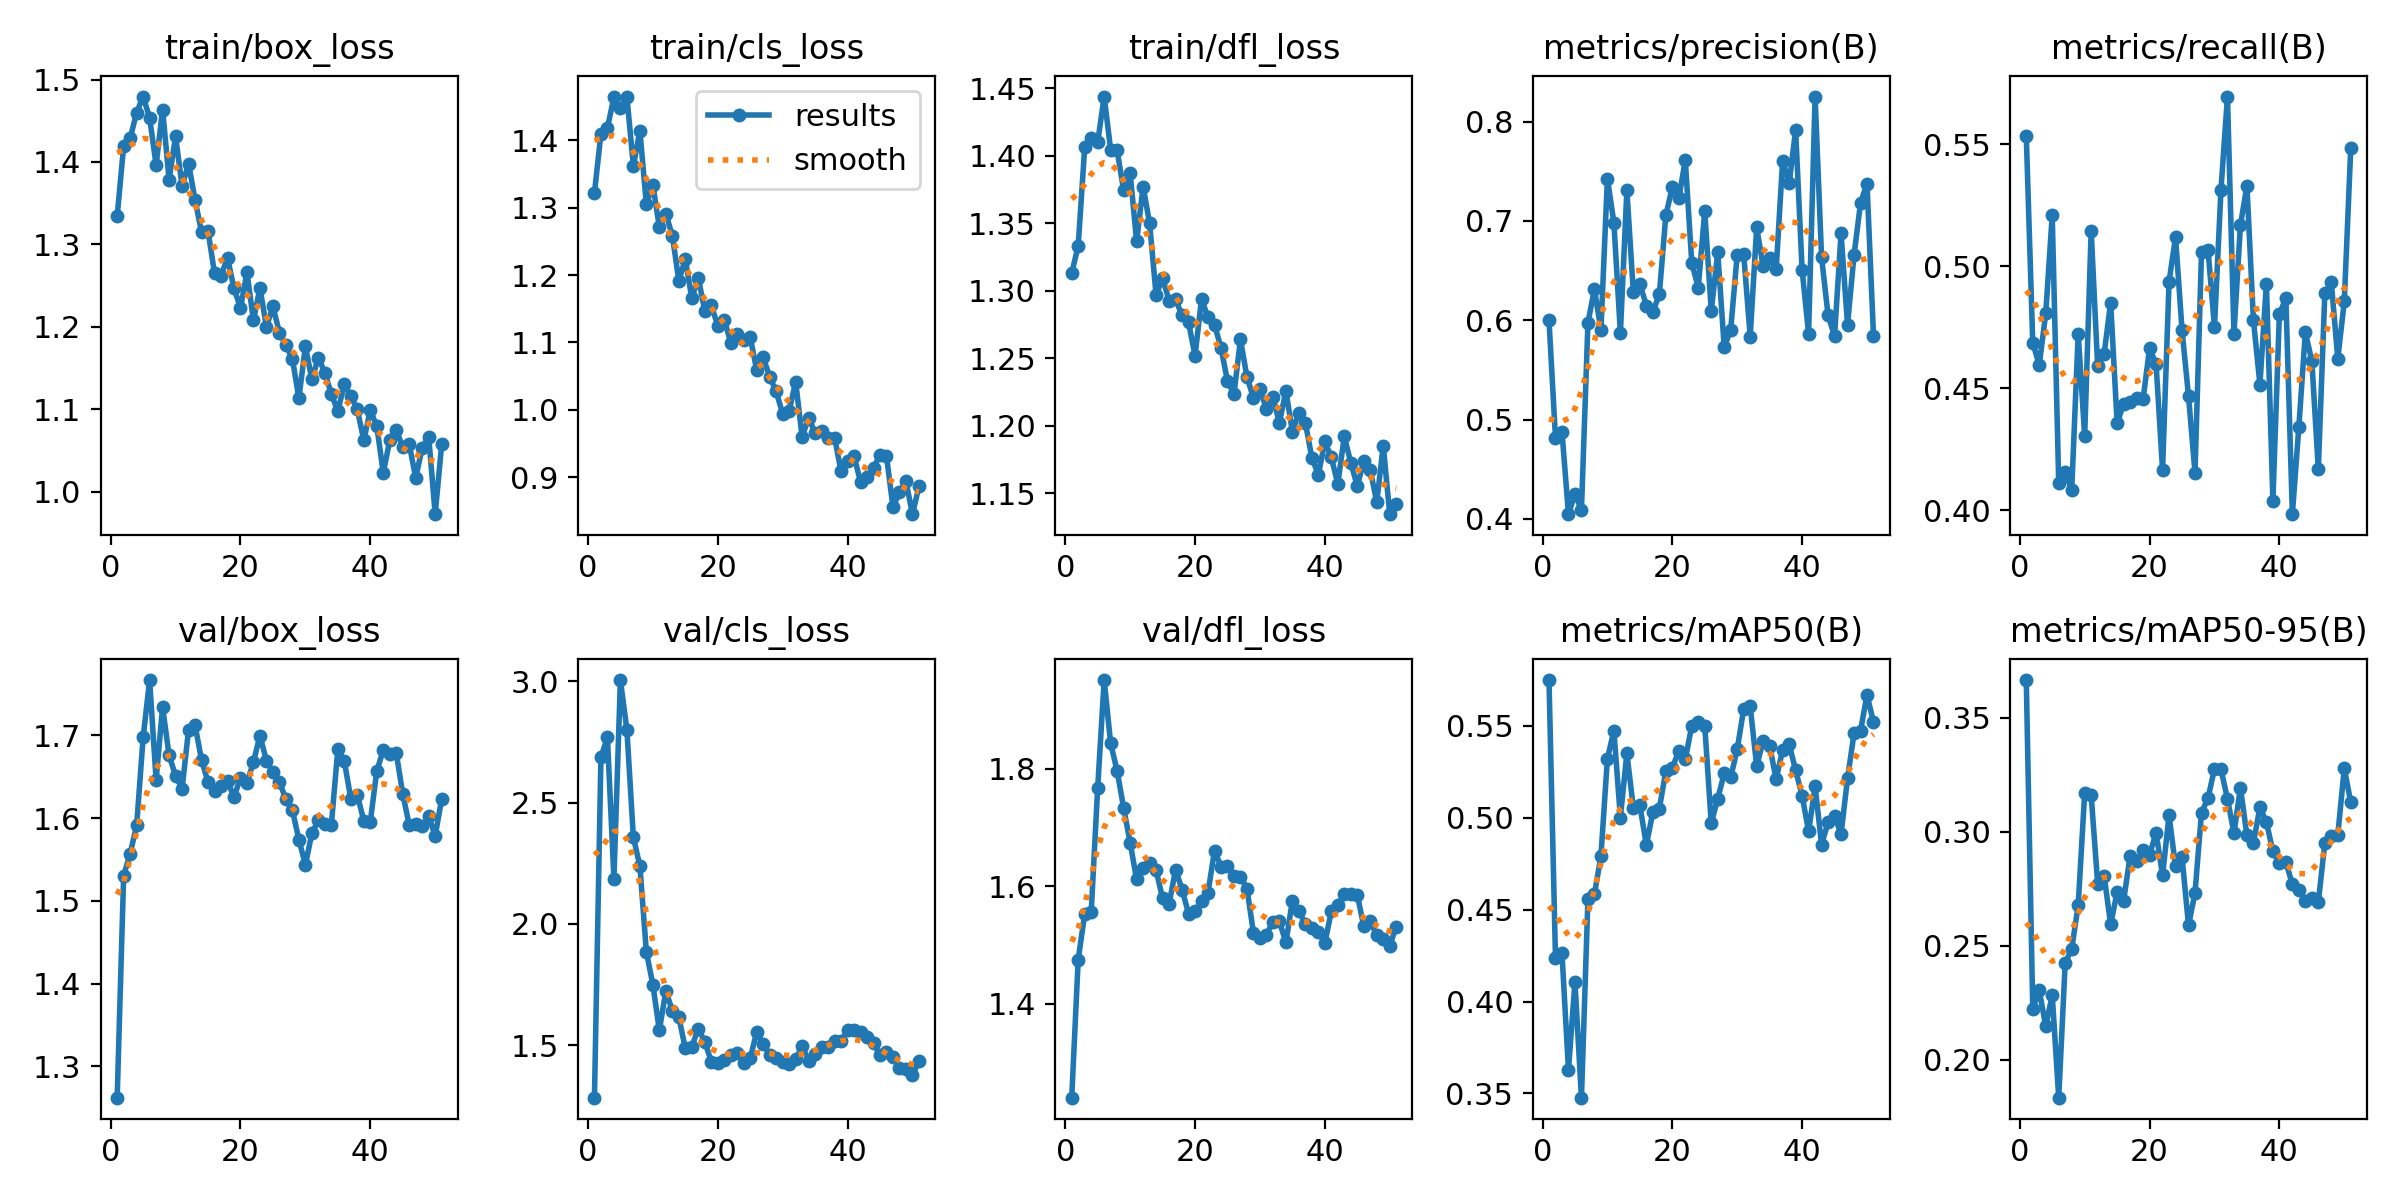

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
from IPython.display import Image, display
display(Image("/content/runs/detect/final/results.png"))

!cd /content/runs/detect && zip -qr /content/final_results.zip final
from google.colab import files
files.download("/content/final_results.zip")

In [8]:
from google.colab import files
from collections import defaultdict
import cv2, numpy as np
from ultralytics import YOLO

#영상 업로드하기
up = files.upload()
video = "/content/" + list(up.keys())[0]

model = YOLO("/content/runs/detect/final/weights/best.pt")

cap = cv2.VideoCapture(video)
fps = cap.get(cv2.CAP_PROP_FPS) or 30
ok, frame = cap.read()
h, w = frame.shape[:2]
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
out = cv2.VideoWriter("/content/result.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
history = defaultdict(list)

for _ in range(int(fps * 5)):
    ok, frame = cap.read()
    if not ok: break
    r = model.track(frame, persist=True, tracker="bytetrack.yaml", conf=0.3, verbose=False)[0]
    img = r.plot()
    if r.boxes.id is not None:
        for (x, y, bw, bh), tid in zip(r.boxes.xywh.cpu(), r.boxes.id.int().cpu().tolist()):
            history[tid].append((float(x), float(y)))
            pts = np.array(history[tid][-30:], np.int32).reshape(-1, 1, 2)
            cv2.polylines(img, [pts], False, (0, 255, 255), 3)
    out.write(img)

cap.release(); out.release()

files.download("/content/result.mp4")

Saving MLhw_video.mp4 to MLhw_video.mp4
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 199ms
Prepared 1 package in 57ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

완료! 추적된 객체 수: 25


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>